# EDA: Panoptic Indoor Segmentation v5

Eksplorasi dataset latih (Roboflow `panopticindoor/panoptic-indoor-segmentation` v5) dan perbandingannya dengan test set foto HP.
Tidak butuh GPU.

## 0. Konfigurasi

In [1]:
RF_WORKSPACE, RF_PROJECT, RF_VERSION = "panopticindoor", "panoptic-indoor-segmentation", 5
TEST_WORKSPACE, TEST_PROJECT, TEST_VERSION = "ghazanfar-latief", "panoptic-indoor-segmentation-rlrwm", 1
HAS_OWN = True

MERGE = {
    "ligjt": "light", "liht": "light", "llight": "light",
    "persob": "person",
    "spon": "spoon", "spoom": "spoon",
    "cuo": "cup", "cyo": "cup",
    "palte": "plate",
    "pap": "paper", "paper-merged": "paper",
    "staris": "stairs",
    "stovv": "stove-merged",
    "towl": "towel",
    "scissor": "scissors",
    "phone": "cell phone",
    "ruf": "rug-merged",
    "windo": "window-other",
}
DROP = []

STUFF_HINTS = ("-merged", "-stuff", "wall", "floor", "ceiling")

## 1. Setup

In [2]:
!pip install -q roboflow

import os, glob, json, yaml, collections, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from kaggle_secrets import UserSecretsClient

OUT = "/kaggle/working/EDA"
DATA = "/tmp/data"
os.makedirs(OUT, exist_ok=True)
SPLITS = ["train", "valid", "test"]
random.seed(0)

def save(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}.png", dpi=120); plt.show()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Fungsi bantu

In [3]:
def load_names(yaml_path):
    n = yaml.safe_load(open(yaml_path))["names"]
    return list(n.values()) if isinstance(n, dict) else list(n)

def label_counts(root, names, split="*"):
    cnt = collections.Counter()
    for f in glob.glob(f"{root}/{split}/labels/*.txt"):
        cnt.update(names[int(l.split()[0])] for l in open(f) if l.strip())
    return cnt

def class_table(root, names):
    return (pd.DataFrame({s: label_counts(root, names, s) for s in SPLITS})
              .reindex(columns=SPLITS).fillna(0).astype(int).sort_values("train", ascending=False))

def merge_yolo(root, merge, drop):
    old = load_names(f"{root}/data.yaml")
    new_names = sorted({merge.get(n, n) for n in old} - set(drop))
    idx = {i: new_names.index(merge.get(n, n)) for i, n in enumerate(old) if merge.get(n, n) not in drop}
    for lab in glob.glob(f"{root}/*/labels/*.txt"):
        rows = [l.split() for l in open(lab) if l.strip()]
        with open(lab, "w") as f:
            f.writelines(" ".join([str(idx[int(r[0])])] + r[1:]) + "\n" for r in rows if int(r[0]) in idx)
    d = yaml.safe_load(open(f"{root}/data.yaml"))
    d["names"], d["nc"] = new_names, len(new_names)
    yaml.safe_dump(d, open(f"{root}/data.yaml", "w"))
    return new_names

def merge_coco(root, merge, drop, names):
    cats = [{"id": i + 1, "name": n, "supercategory": "none"} for i, n in enumerate(names)]
    by_name = {c["name"]: c["id"] for c in cats}
    for p in glob.glob(f"{root}/*/_annotations.coco.json"):
        d = json.load(open(p))
        id2new = {c["id"]: merge.get(c["name"], c["name"]) for c in d["categories"]}
        d["annotations"] = [{**a, "category_id": by_name[id2new[a["category_id"]]]}
                            for a in d["annotations"] if id2new[a["category_id"]] not in drop]
        d["categories"] = cats
        json.dump(d, open(p, "w"))

def is_stuff(name):
    return any(h in name for h in STUFF_HINTS)

## 3. Download dan merge kelas

In [4]:
from roboflow import Roboflow
rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))
ver = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
YOLO_ROOT = ver.download("yolov8", location=f"{DATA}/yolo", overwrite=True).location
COCO_ROOT = ver.download("coco",   location=f"{DATA}/coco", overwrite=True).location

RAW_NAMES = load_names(f"{YOLO_ROOT}/data.yaml")
raw_cls = class_table(YOLO_ROOT, RAW_NAMES)
NAMES = merge_yolo(YOLO_ROOT, MERGE, DROP)
merge_coco(COCO_ROOT, MERGE, DROP, NAMES)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /tmp/data/yolo in yolov8:: 100%|██████████| 1856/1856 [00:00<00:00, 5346.30it/s]


Extracting Dataset Version Zip to /tmp/data/coco in coco:: 100%|██████████| 930/930 [00:00<00:00, 4349.78it/s]


## 4. Ringkasan dataset

In [5]:
D = {s: json.load(open(f"{COCO_ROOT}/{s}/_annotations.coco.json")) for s in SPLITS}

rows = []
for s, d in D.items():
    per_img = collections.Counter(a["image_id"] for a in d["annotations"])
    rows.append({"split": s, "gambar": len(d["images"]), "objek": len(d["annotations"]),
                 "gambar tanpa objek": sum(per_img[im["id"]] == 0 for im in d["images"]),
                 "objek per gambar": round(len(d["annotations"]) / max(len(d["images"]), 1), 2),
                 "kelas terpakai": len({a["category_id"] for a in d["annotations"]})})
overview = pd.DataFrame(rows).set_index("split")
overview.loc["total"] = overview.sum(numeric_only=True)
overview.loc["total", "objek per gambar"] = round(overview.loc["total", "objek"] / overview.loc["total", "gambar"], 2)
overview.loc["total", "kelas terpakai"] = len(NAMES)
overview.to_csv(f"{OUT}/ringkasan.csv"); display(overview)

sizes = pd.Series(collections.Counter(f'{im["width"]}x{im["height"]}' for d in D.values() for im in d["images"]),
                  name="jumlah gambar").sort_values(ascending=False)
print("Resolusi gambar:"); display(sizes.head(10))

merged = {k: v for k, v in MERGE.items() if k in raw_cls.index}
print(f"Kelas: {len(RAW_NAMES)} sebelum merge, {len(NAMES)} setelah merge. Yang digabung: {merged}")

,gambar,objek,gambar tanpa objek,objek per gambar,kelas terpakai
split,,,,,
train,397.0,4479.0,0.0,11.28,64.0
valid,166.0,2022.0,1.0,12.18,57.0
test,359.0,5344.0,0.0,14.89,67.0
total,922.0,11845.0,1.0,12.85,72.0


Resolusi gambar:


640x480      511
960x1280      31
640x640       29
750x500       24
225x225       13
275x183       12
720x1280       8
1024x1024      6
1500x1000      6
720x480        5
Name: jumlah gambar, dtype: int64

Kelas: 74 sebelum merge, 72 setelah merge. Yang digabung: {'paper-merged': 'paper', 'scissor': 'scissors'}


## 5. Distribusi kelas

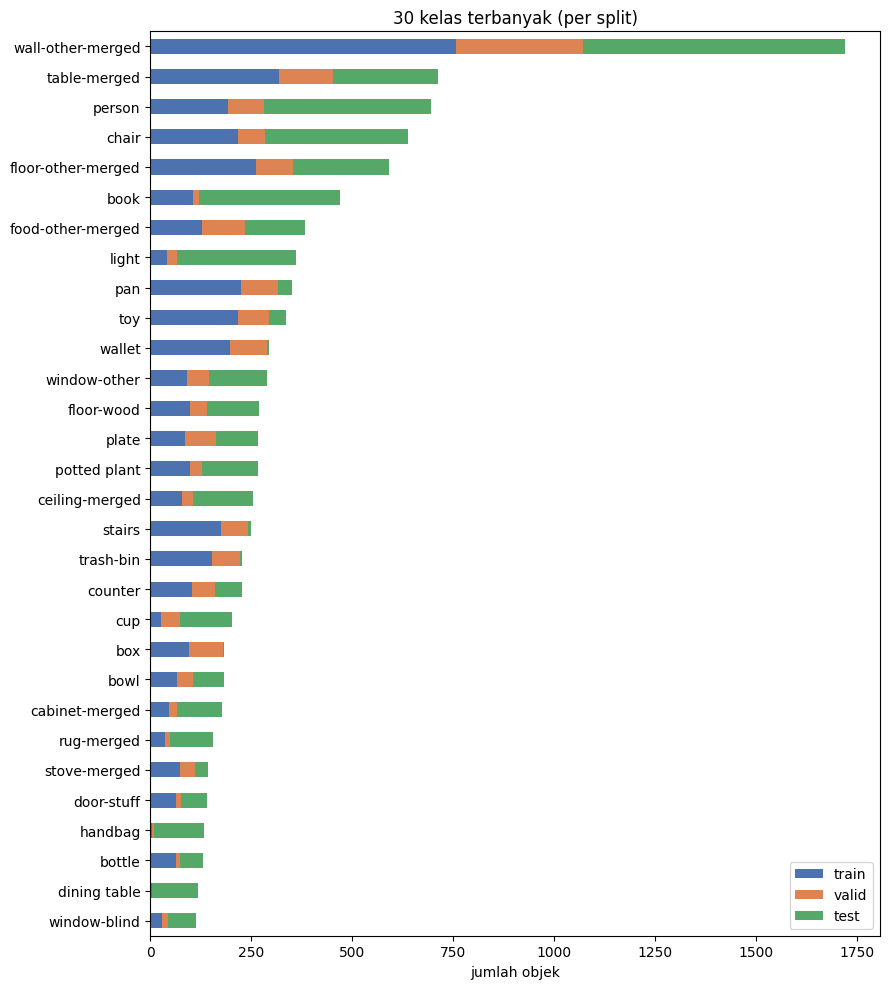

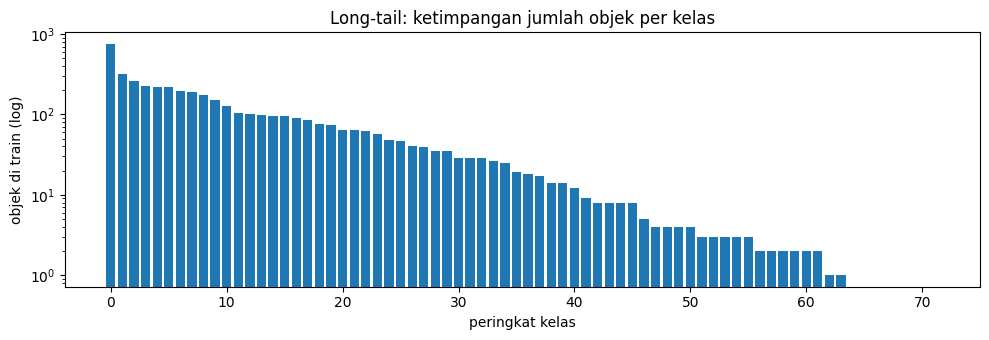

5 kelas terbanyak menyumbang 39.7% objek train


In [6]:
cls = class_table(YOLO_ROOT, NAMES)
cls["total"] = cls.sum(axis=1)
cls["stuff/thing"] = ["stuff" if is_stuff(n) else "thing" for n in cls.index]
cls.to_csv(f"{OUT}/distribusi_kelas.csv")

top = cls.sort_values("total", ascending=False).head(30)[SPLITS][::-1]
top.plot.barh(stacked=True, figsize=(9, 10), color=["#4C72B0", "#DD8452", "#55A868"])
plt.xlabel("jumlah objek"); plt.title("30 kelas terbanyak (per split)")
save("distribusi_kelas_top30")

c = cls["train"].sort_values(ascending=False)
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(c)), c.values); plt.yscale("log")
plt.xlabel("peringkat kelas"); plt.ylabel("objek di train (log)"); plt.title("Long-tail: ketimpangan jumlah objek per kelas")
save("long_tail")
print(f"5 kelas terbanyak menyumbang {100 * c.head(5).sum() / c.sum():.1f}% objek train")

## 6. Ketidaksesuaian antar split

8 kelas TIDAK ada di train tapi muncul di valid/test (model tidak mungkin mengenalinya):


,train,valid,test
toaster,0,1,4
keyboard,0,0,7
mouse,0,0,8
flower,0,0,6
toothbrush,0,0,14
scissors,0,0,8
hair drier,0,0,2
teddy bear,0,0,6


17 kelas sangat jarang di train (< 5 objek):


,train,valid,test
fork,4,1,24
wall-stone,4,0,2
dining table,4,1,112
vase,4,0,39
oven,3,3,13
backpack,3,2,31
microwave,3,1,7
curtain,3,0,107
clock,3,0,4
refrigerator,2,6,5


5 kelas ada di train tapi tidak muncul di test.


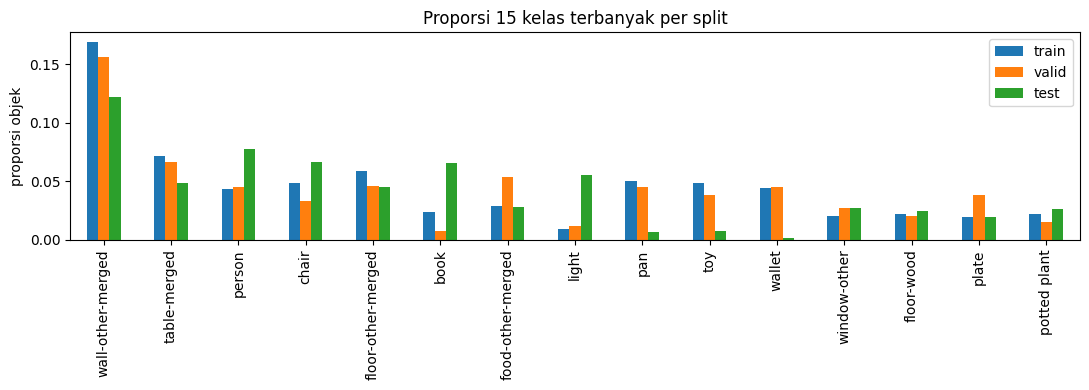

In [7]:
only_eval = cls[(cls["train"] == 0) & ((cls["valid"] > 0) | (cls["test"] > 0))]
rare = cls[(cls["train"] > 0) & (cls["train"] < 5)]
not_in_test = cls[(cls["train"] > 0) & (cls["test"] == 0)]

print(f"{len(only_eval)} kelas TIDAK ada di train tapi muncul di valid/test (model tidak mungkin mengenalinya):")
display(only_eval[SPLITS])
print(f"{len(rare)} kelas sangat jarang di train (< 5 objek):")
display(rare[SPLITS])
print(f"{len(not_in_test)} kelas ada di train tapi tidak muncul di test.")

share = (cls[SPLITS] / cls[SPLITS].sum()).loc[cls["total"].sort_values(ascending=False).head(15).index]
share.plot.bar(figsize=(11, 4)); plt.ylabel("proporsi objek"); plt.title("Proporsi 15 kelas terbanyak per split")
save("proporsi_kelas_per_split")

pd.concat({"hanya_valid_test": only_eval[SPLITS], "jarang_di_train": rare[SPLITS]}).to_csv(f"{OUT}/kelas_bermasalah.csv")

## 7. Ukuran objek

ukuran COCO,small,medium,large
split,,,
test,0.107,0.319,0.573
train,0.110,0.314,0.576
valid,0.096,0.336,0.568


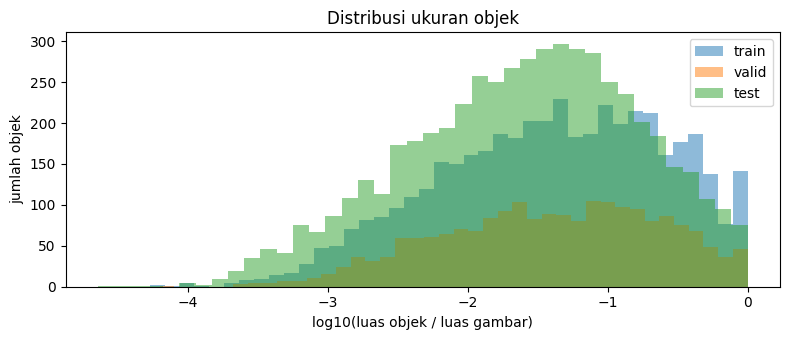

10 kelas dengan objek terkecil:


,objek,median luas relatif
kelas,,
light,360,0.002561
remote,10,0.002815
knife,36,0.003519
clock,7,0.003708
book,469,0.003983
mouse,8,0.004286
vase,43,0.006673
handbag,133,0.006774
toothbrush,14,0.006855


In [8]:
id2name = {i + 1: n for i, n in enumerate(NAMES)}
recs = []
for s, d in D.items():
    imgs = {im["id"]: im for im in d["images"]}
    for a in d["annotations"]:
        im = imgs[a["image_id"]]
        x, y, w, h = a["bbox"]
        recs.append({"split": s, "kelas": id2name[a["category_id"]], "area": a["area"],
                     "area_rel": a["area"] / (im["width"] * im["height"]),
                     "cx": (x + w / 2) / im["width"], "cy": (y + h / 2) / im["height"],
                     "image_id": a["image_id"]})
A = pd.DataFrame(recs)
A["ukuran COCO"] = pd.cut(A["area"], [-1, 32 ** 2, 96 ** 2, np.inf], labels=["small", "medium", "large"])

size_tab = pd.crosstab(A["split"], A["ukuran COCO"], normalize="index").round(3)
display(size_tab); size_tab.to_csv(f"{OUT}/ukuran_objek_per_split.csv")

plt.figure(figsize=(8, 3.5))
for s in SPLITS:
    plt.hist(np.log10(A.loc[A["split"] == s, "area_rel"].clip(lower=1e-6)), bins=40, alpha=0.5, label=s)
plt.xlabel("log10(luas objek / luas gambar)"); plt.ylabel("jumlah objek"); plt.legend(); plt.title("Distribusi ukuran objek")
save("ukuran_objek")

per_cls = (A.groupby("kelas")["area_rel"].agg(["count", "median"]).sort_values("median")
             .rename(columns={"count": "objek", "median": "median luas relatif"}))
per_cls.to_csv(f"{OUT}/ukuran_per_kelas.csv")
print("10 kelas dengan objek terkecil:"); display(per_cls.head(10))

## 8. Kepadatan objek dan posisi

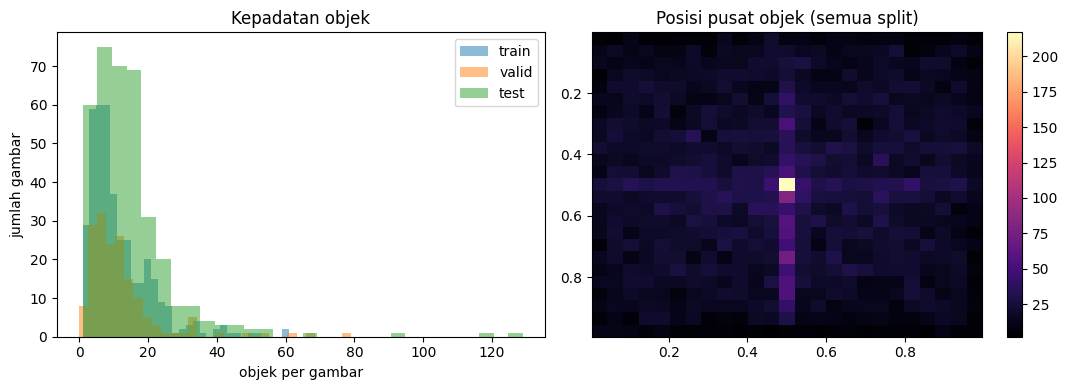

tipe,stuff,thing
split,,
test,2032,3312
train,2149,2330
valid,929,1093


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for s in SPLITS:
    per_img = collections.Counter(a["image_id"] for a in D[s]["annotations"])
    ax[0].hist([per_img[im["id"]] for im in D[s]["images"]], bins=30, alpha=0.5, label=s)
ax[0].set_xlabel("objek per gambar"); ax[0].set_ylabel("jumlah gambar"); ax[0].legend(); ax[0].set_title("Kepadatan objek")
h = ax[1].hist2d(A["cx"], A["cy"], bins=25, cmap="magma")
ax[1].invert_yaxis(); ax[1].set_title("Posisi pusat objek (semua split)"); fig.colorbar(h[3], ax=ax[1])
save("kepadatan_dan_posisi")

st = A.assign(tipe=A["kelas"].map(lambda n: "stuff" if is_stuff(n) else "thing"))
display(pd.crosstab(st["split"], st["tipe"]))

## 9. Contoh anotasi

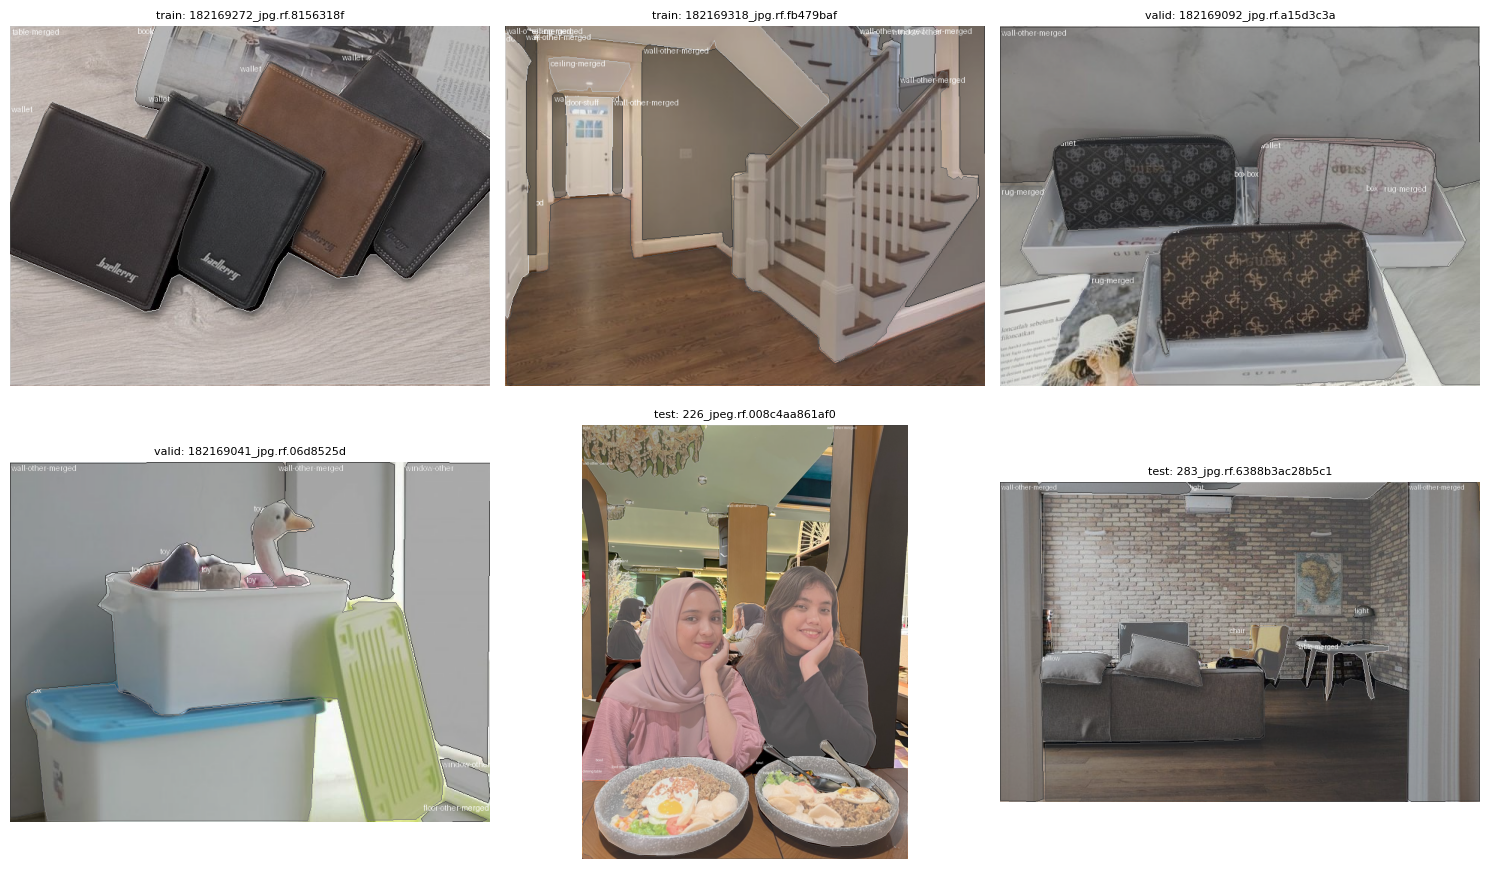

In [10]:
def draw(split, im, ax):
    img = Image.open(f"{COCO_ROOT}/{split}/{im['file_name']}").convert("RGB")
    over = Image.new("RGBA", img.size, (0, 0, 0, 0)); dr = ImageDraw.Draw(over)
    for a in D[split]["annotations"]:
        if a["image_id"] != im["id"]:
            continue
        col = tuple(random.Random(a["category_id"]).randint(40, 255) for _ in range(3))
        for poly in a.get("segmentation") or []:
            if len(poly) >= 6:
                dr.polygon(poly, fill=col + (110,), outline=col + (255,))
        dr.text((a["bbox"][0] + 2, a["bbox"][1] + 2), id2name[a["category_id"]], fill=(255, 255, 255, 255))
    ax.imshow(Image.alpha_composite(img.convert("RGBA"), over)); ax.axis("off"); ax.set_title(f"{split}: {im['file_name'][:25]}", fontsize=8)

picks = [(s, im) for s in SPLITS for im in random.sample(D[s]["images"], min(2, len(D[s]["images"])))]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for (s, im), ax in zip(picks, axes.flat):
    draw(s, im, ax)
save("contoh_anotasi")

## 10. Dataset asli vs foto HP

loading Roboflow workspace...
loading Roboflow project...
Exporting format coco in progress : 95.0%
Version export complete for coco format



Extracting Dataset Version Zip to /tmp/data/own_coco in coco:: 100%|██████████| 927/927 [00:00<00:00, 4025.54it/s]


0 foto HP, 0 objek


invalid value encountered in divide


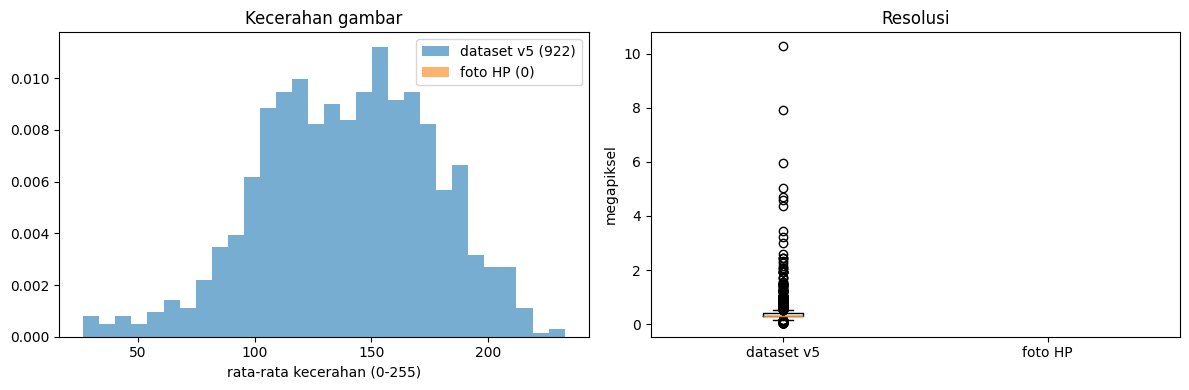

Kelas di foto HP yang tidak ada di data latih: tidak ada


Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`


,train v5,foto HP,proporsi train,proporsi HP
wall-other-merged,756,0,0.169,NaN
table-merged,319,0,0.071,NaN
floor-other-merged,261,0,0.058,NaN
pan,225,0,0.050,NaN
toy,217,0,0.048,NaN
chair,217,0,0.048,NaN
wallet,197,0,0.044,NaN
person,192,0,0.043,NaN
stairs,175,0,0.039,NaN
trash-bin,153,0,0.034,NaN


,dataset v5,foto HP
25%,113.8,NaN
50%,141.6,NaN
75%,166.4,NaN
count,922.0,0
freq,NaN,NaN
max,232.7,NaN
mean,139.6,NaN
min,26.7,NaN
std,37.0,NaN
top,NaN,NaN


In [11]:
def brightness(path):
    return np.asarray(Image.open(path).convert("L").resize((128, 128))).mean()

if HAS_OWN:
    tv = rf.workspace(TEST_WORKSPACE).project(TEST_PROJECT).version(TEST_VERSION)
    own_root = tv.download("coco", location=f"{DATA}/own_coco", overwrite=True).location
    base = lambda p: os.path.basename(p).split(".rf.")[0]
    v5 = {base(im["file_name"]) for d in D.values() for im in d["images"]}

    own_imgs, own_cls = [], collections.Counter()
    for p in glob.glob(f"{own_root}/*/_annotations.coco.json"):
        d = json.load(open(p))
        names = {c["id"]: MERGE.get(c["name"], c["name"]) for c in d["categories"]}
        keep = {im["id"]: im for im in d["images"] if base(im["file_name"]) not in v5}
        own_imgs += [(f"{os.path.dirname(p)}/{im['file_name']}", im) for im in keep.values()]
        own_cls.update(names[a["category_id"]] for a in d["annotations"] if a["image_id"] in keep)
    print(len(own_imgs), "foto HP,", sum(own_cls.values()), "objek")

    v5_paths = [f"{COCO_ROOT}/{s}/{im['file_name']}" for s in SPLITS for im in D[s]["images"]]
    b_v5 = [brightness(p) for p in v5_paths]
    b_hp = [brightness(p) for p, _ in own_imgs]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(b_v5, bins=30, alpha=0.6, density=True, label=f"dataset v5 ({len(b_v5)})")
    ax[0].hist(b_hp, bins=30, alpha=0.6, density=True, label=f"foto HP ({len(b_hp)})")
    ax[0].set_xlabel("rata-rata kecerahan (0-255)"); ax[0].legend(); ax[0].set_title("Kecerahan gambar")
    res_v5 = [im["width"] * im["height"] / 1e6 for d in D.values() for im in d["images"]]
    res_hp = [im["width"] * im["height"] / 1e6 for _, im in own_imgs]
    ax[1].boxplot([res_v5, res_hp]); ax[1].set_xticks([1, 2], ["dataset v5", "foto HP"]); ax[1].set_ylabel("megapiksel"); ax[1].set_title("Resolusi")
    save("v5_vs_hp")

    comp = pd.DataFrame({"train v5": cls["train"], "foto HP": pd.Series(own_cls)}).fillna(0).astype(int)
    comp["proporsi train"] = (comp["train v5"] / comp["train v5"].sum()).round(3)
    comp["proporsi HP"] = (comp["foto HP"] / comp["foto HP"].sum()).round(3)
    comp = comp.sort_values("foto HP", ascending=False)
    comp.to_csv(f"{OUT}/kelas_v5_vs_hp.csv")
    unknown = sorted(set(own_cls) - set(NAMES))
    print("Kelas di foto HP yang tidak ada di data latih:", unknown or "tidak ada")
    display(comp.head(20))
    display(pd.DataFrame({"dataset v5": pd.Series(b_v5).describe(), "foto HP": pd.Series(b_hp).describe()}).round(1))

## 11. File hasil

In [12]:
for f in sorted(os.listdir(OUT)):
    print(f)

contoh_anotasi.png
distribusi_kelas.csv
distribusi_kelas_top30.png
kelas_bermasalah.csv
kelas_v5_vs_hp.csv
kepadatan_dan_posisi.png
long_tail.png
proporsi_kelas_per_split.png
ringkasan.csv
ukuran_objek.png
ukuran_objek_per_split.csv
ukuran_per_kelas.csv
v5_vs_hp.png
